#### **ML Lab-7**
#### Name: Yashmi Patle
#### Section: A
#### Batch:A1
#### Roll No.:15

In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report,ConfusionMatrixDisplay,precision_score,recall_score,f1_score

In [47]:
pd.set_option('display.max_columns',None)

In [48]:
df=pd.read_excel('Raisin_Dataset.xlsx')

In [49]:
df.head()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
0,87524,442.246011,253.291155,0.819738,90546,0.758651,1184.040,Kecimen
1,75166,406.690687,243.032436,0.801805,78789,0.684130,1121.786,Kecimen
2,90856,442.267048,266.328318,0.798354,93717,0.637613,1208.575,Kecimen
3,45928,286.540559,208.760042,0.684989,47336,0.699599,844.162,Kecimen
4,79408,352.190770,290.827533,0.564011,81463,0.792772,1073.251,Kecimen


In [50]:
df.tail()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
895,83248,430.077308,247.838695,0.817263,85839,0.668793,1129.072,Besni
896,87350,440.735698,259.293149,0.808629,90899,0.636476,1214.252,Besni
897,99657,431.706981,298.837323,0.721684,106264,0.741099,1292.828,Besni
898,93523,476.344094,254.176054,0.845739,97653,0.658798,1258.548,Besni
899,85609,512.081774,215.271976,0.907345,89197,0.632020,1272.862,Besni


In [51]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             900 non-null    int64  
 1   MajorAxisLength  900 non-null    float64
 2   MinorAxisLength  900 non-null    float64
 3   Eccentricity     900 non-null    float64
 4   ConvexArea       900 non-null    int64  
 5   Extent           900 non-null    float64
 6   Perimeter        900 non-null    float64
 7   Class            900 non-null    object 
dtypes: float64(5), int64(2), object(1)
memory usage: 56.4+ KB


In [52]:
df.describe()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter
count,900.000000,900.000000,900.000000,900.000000,900.000000,900.000000,900.000000
mean,87804.127778,430.929950,254.488133,0.781542,91186.090000,0.699508,1165.906636
std,39002.111390,116.035121,49.988902,0.090318,40769.290132,0.053468,273.764315
min,25387.000000,225.629541,143.710872,0.348730,26139.000000,0.379856,619.074000
25%,59348.000000,345.442898,219.111126,0.741766,61513.250000,0.670869,966.410750
50%,78902.000000,407.803951,247.848409,0.798846,81651.000000,0.707367,1119.509000
75%,105028.250000,494.187014,279.888575,0.842571,108375.750000,0.734991,1308.389750
max,235047.000000,997.291941,492.275279,0.962124,278217.000000,0.835455,2697.753000


In [53]:
df.isnull().sum()

,0
Area,0
MajorAxisLength,0
MinorAxisLength,0
Eccentricity,0
ConvexArea,0
Extent,0
Perimeter,0
Class,0


In [54]:
df.dtypes

,0
Area,int64
MajorAxisLength,float64
MinorAxisLength,float64
Eccentricity,float64
ConvexArea,int64
Extent,float64
Perimeter,float64
Class,object


In [55]:
df.duplicated().sum()

np.int64(0)

In [56]:
df['Class'].unique()

array(['Kecimen', 'Besni'], dtype=object)

In [57]:
df['Class'].value_counts()

,count
Class,
Kecimen,450
Besni,450


**BAR PLOT**

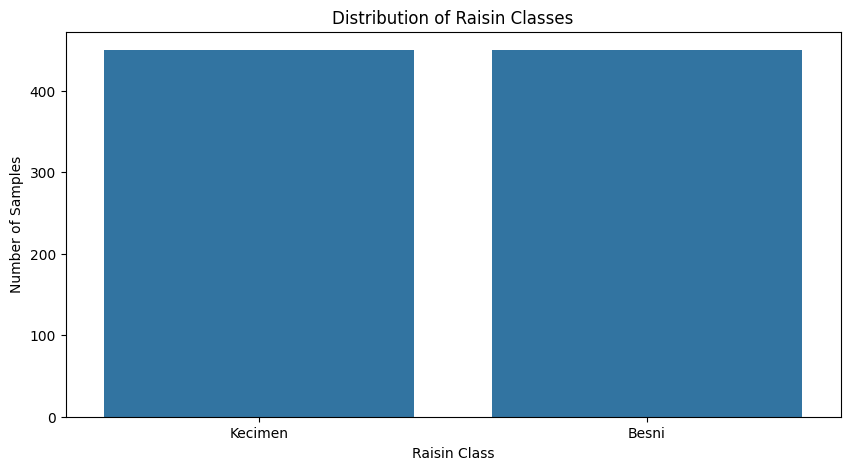

In [58]:
plt.figure(figsize=(10,5))
sns.countplot(x="Class",data=df)
plt.title("Distribution of Raisin Classes")
plt.xlabel("Raisin Class")
plt.ylabel("Number of Samples")
plt.show()

**PIE-CHART**

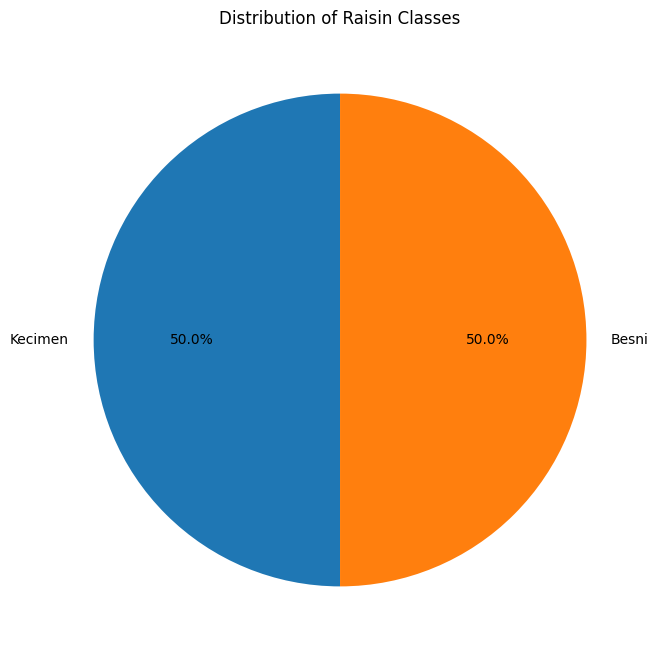

In [59]:
class_counts = df['Class'].value_counts()
plt.figure(figsize=(8, 8))
plt.pie(class_counts, labels=class_counts.index, autopct='%1.1f%%', startangle=90)
plt.title('Distribution of Raisin Classes')
plt.show()

In [60]:
numerical_features=df.select_dtypes(include=np.number).columns
print(numerical_features.tolist())

['Area', 'MajorAxisLength', 'MinorAxisLength', 'Eccentricity', 'ConvexArea', 'Extent', 'Perimeter']


**HISTOGRAM**

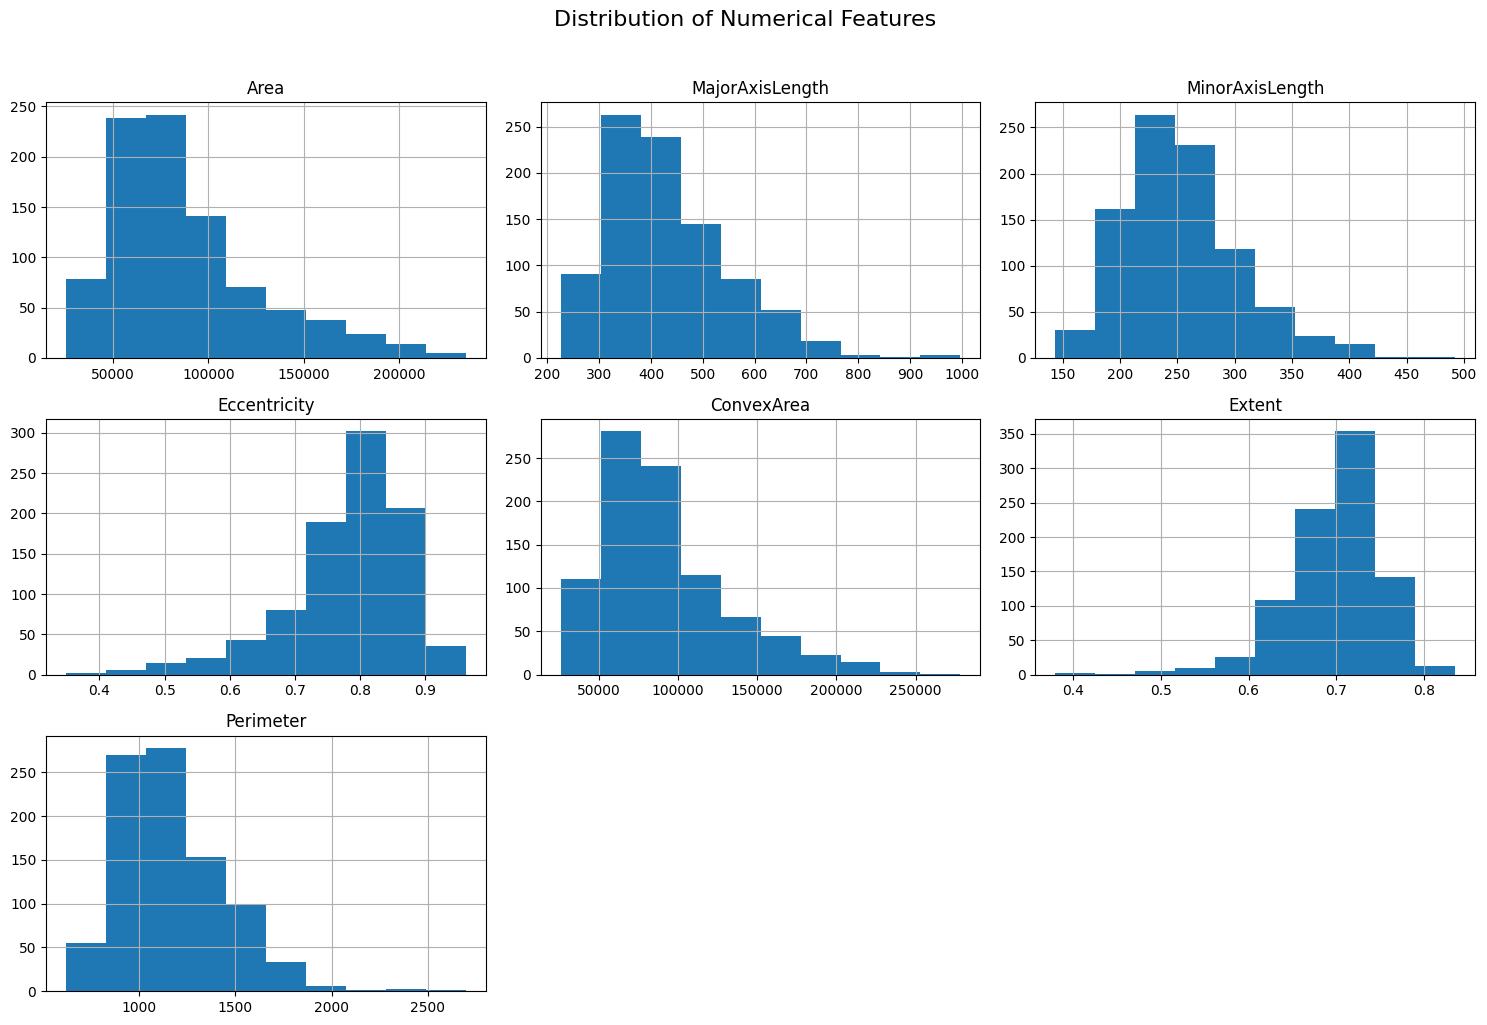

In [61]:
df[numerical_features].hist(figsize=(15,10))
plt.suptitle("Distribution of Numerical Features",y=1.02,fontsize=16)
plt.tight_layout()
plt.show()

**BOX PLOT**

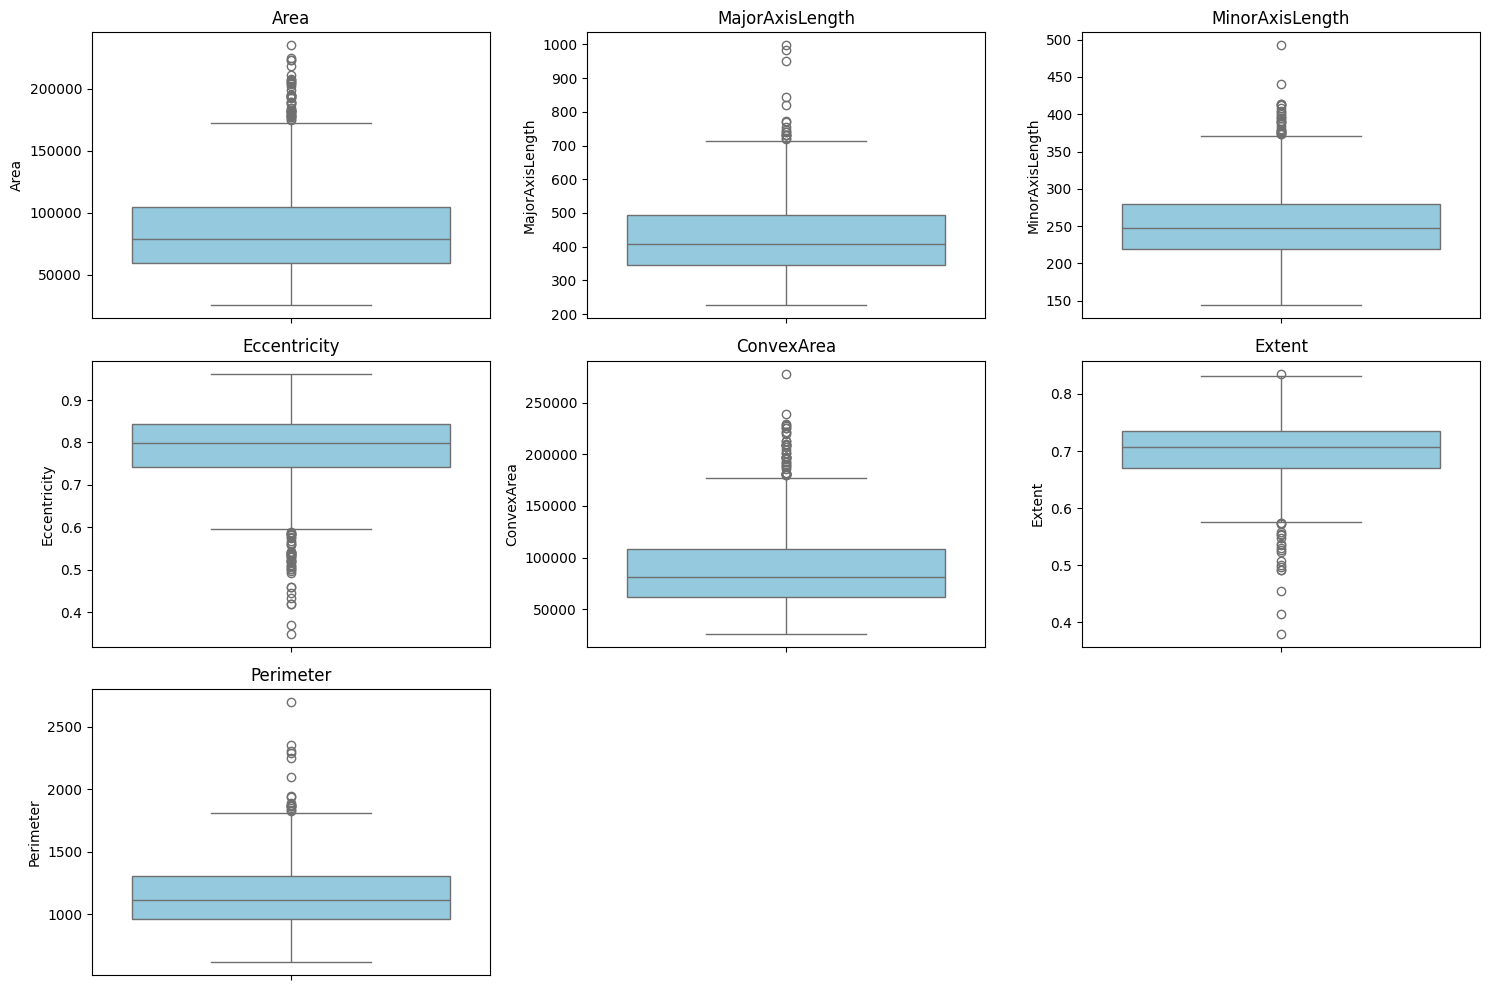

In [62]:
plt.figure(figsize=(15,10))
for i,column in enumerate(numerical_features):
    plt.subplot(3,3,i+1)
    sns.boxplot(y=df[column],color='skyblue')
    plt.tight_layout()
    plt.title(column)
plt.tight_layout()
plt.show()

**HISTOGRAM WITH KDE FUNCTION**

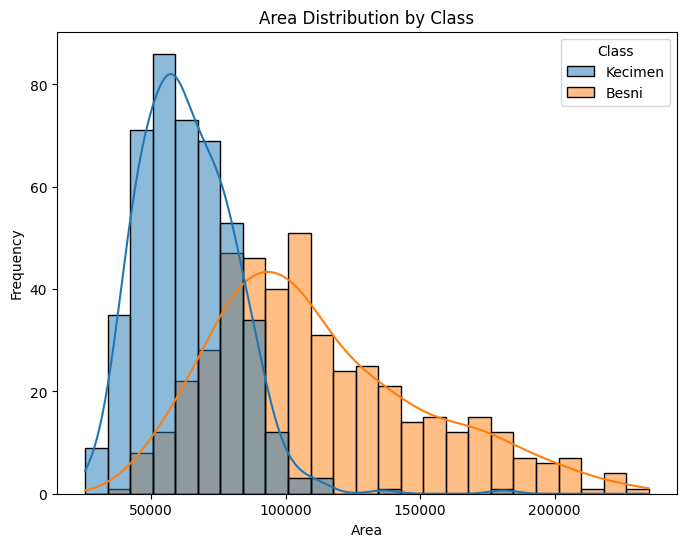

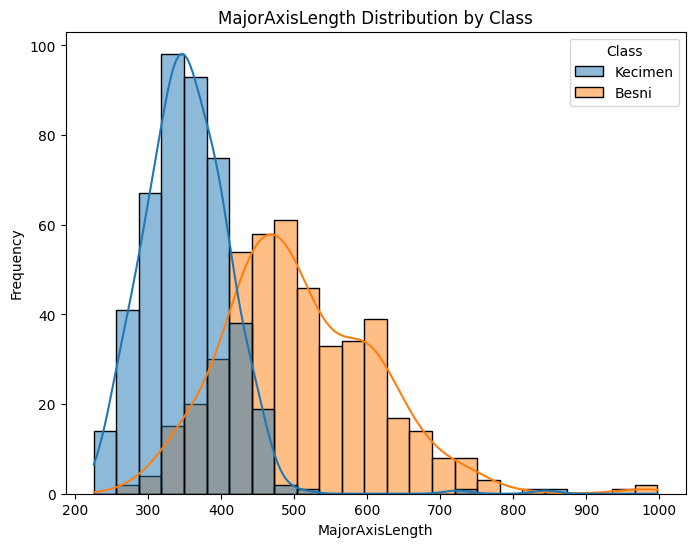

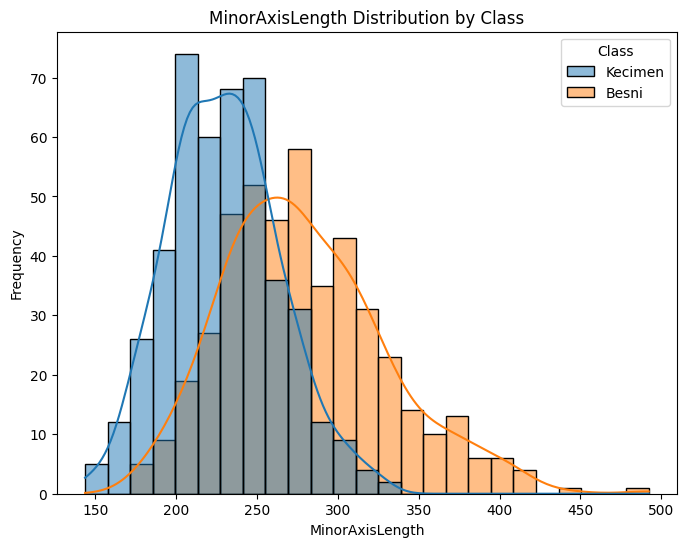

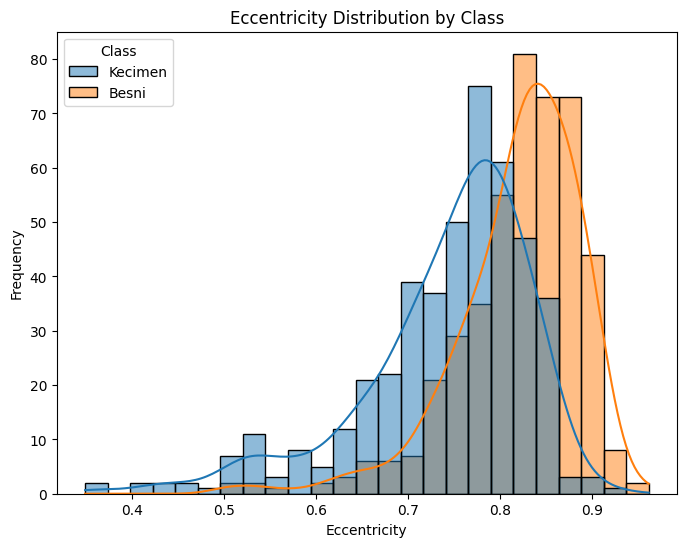

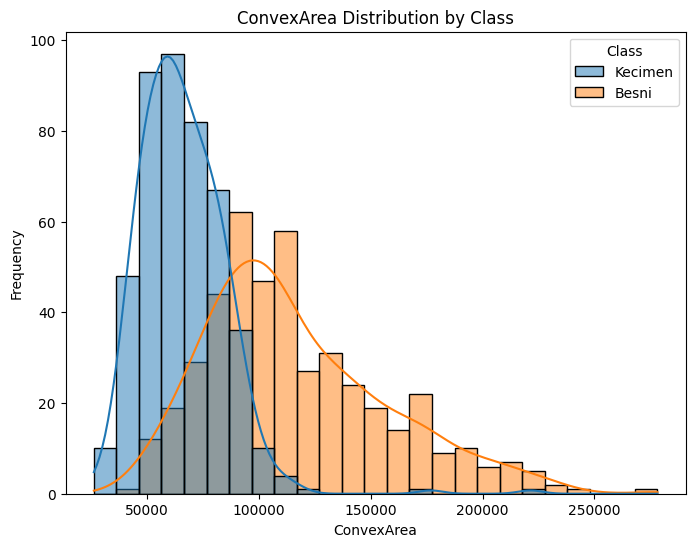

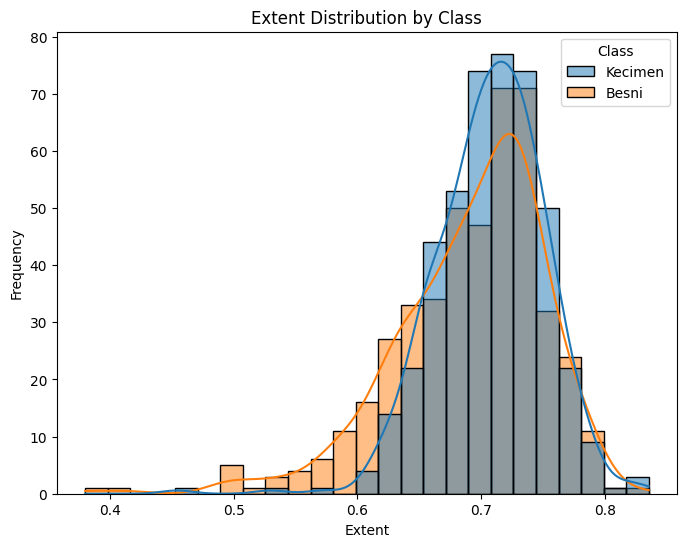

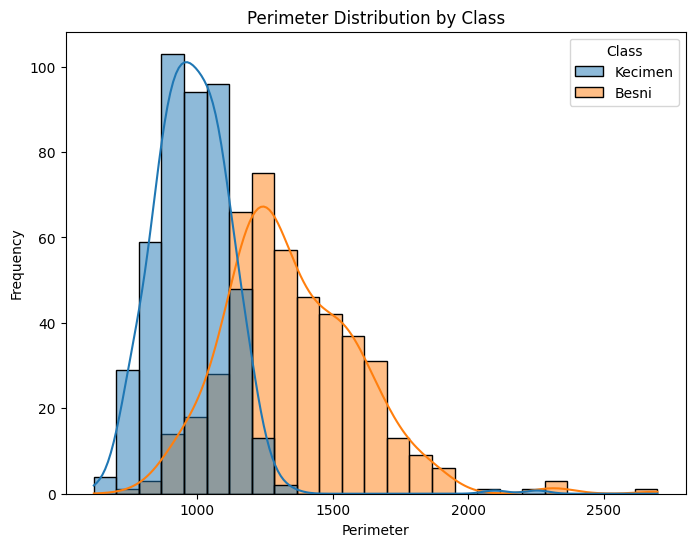

In [63]:
for column in numerical_features:
    plt.figure(figsize=(8,6))
    sns.histplot(data=df,x=column,hue="Class",kde=True,bins=25)
    plt.title(f"{column} Distribution by Class")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.show()

**CORRELATION MATRIX**

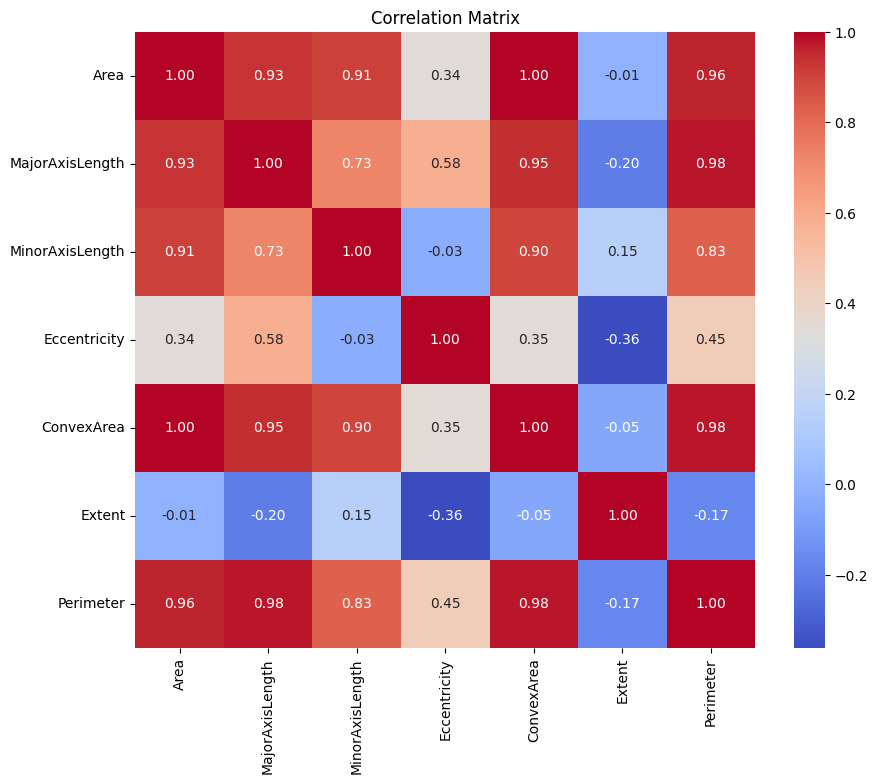

In [64]:
correlation_matrix=df[numerical_features].corr()
plt.figure(figsize=(10,8))
sns.heatmap(correlation_matrix,annot=True,cmap='coolwarm',fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

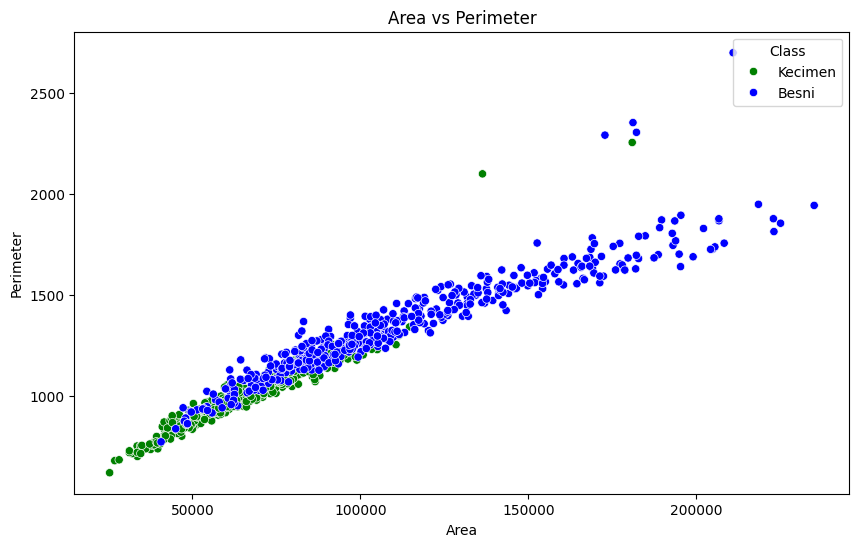

In [65]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=df,x='Area',y='Perimeter',palette={'Kecimen':'Green','Besni':'blue'},hue='Class')
plt.title("Area vs Perimeter")
plt.xlabel("Area")
plt.ylabel("Perimeter")
plt.show()

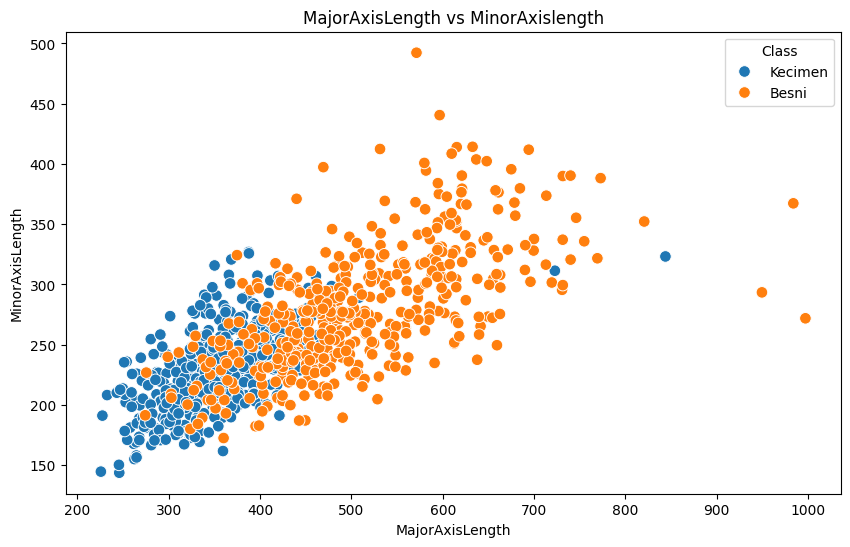

In [66]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=df,x='MajorAxisLength',y='MinorAxisLength',s=70,hue='Class')
plt.title("MajorAxisLength vs MinorAxislength")
plt.show()

**DATA PREPROCESSING**

In [67]:
label_encoder=LabelEncoder()
df['Class_encoded']=label_encoder.fit_transform(df['Class'])
print(df[['Class','Class_encoded']].head(10))

     Class  Class_encoded
0  Kecimen              1
1  Kecimen              1
2  Kecimen              1
3  Kecimen              1
4  Kecimen              1
5  Kecimen              1
6  Kecimen              1
7  Kecimen              1
8  Kecimen              1
9  Kecimen              1


In [68]:
print("Class Mapping:")
for index,class_name in enumerate(label_encoder.classes_):
    print(f"{index} : {class_name}")

Class Mapping:
0 : Besni
1 : Kecimen


In [69]:
X=df[numerical_features]
y=df["Class_encoded"]
print("X shape",X.shape)
print("Y shape",y.shape)

X shape (900, 7)
Y shape (900,)


In [70]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
print("Training Samples:",X_train.shape[0])
print("Testing Samples:",X_test.shape[0])

Training Samples: 720
Testing Samples: 180


In [71]:
GaussianNB()

GaussianNB()

In [72]:
gnb=GaussianNB()
gnb.fit(X_train,y_train)

GaussianNB()

In [73]:
y_pred=gnb.predict(X_test)
print(y_pred)

[0 1 1 0 1 1 1 1 1 1 0 0 0 1 0 0 0 1 1 0 1 0 1 1 0 1 1 0 0 0 1 0 0 0 0 0 1
 0 1 1 1 1 1 1 0 0 1 1 1 1 0 1 0 1 1 1 1 1 1 0 1 1 1 1 1 1 0 0 1 1 0 0 1 1
 0 0 1 1 1 0 0 1 0 1 0 0 1 1 1 0 1 1 0 0 0 1 1 1 0 0 0 1 0 1 1 1 0 1 1 1 0
 0 1 1 0 1 1 1 1 0 1 1 1 1 0 1 1 0 1 1 0 0 0 1 1 1 0 0 0 1 1 1 0 1 0 1 0 1
 1 1 1 0 1 1 1 1 1 1 1 1 1 0 1 1 0 0 1 0 0 0 1 1 1 1 0 0 0 0 1 1]


In [74]:
comparison=pd.DataFrame({'Actual':y_test,'Predicted':y_pred})
print(comparison.head(10))

     Actual  Predicted
70        1          0
827       0          1
231       1          1
588       0          0
39        1          1
731       0          1
299       1          1
110       1          1
72        1          1
86        1          1


In [75]:
comparison["Actual Class"]=label_encoder.inverse_transform(comparison["Actual"])
comparison["Predicted Class"]=label_encoder.inverse_transform(comparison["Predicted"])
print(comparison.head(10))

     Actual  Predicted Actual Class Predicted Class
70        1          0      Kecimen           Besni
827       0          1        Besni         Kecimen
231       1          1      Kecimen         Kecimen
588       0          0        Besni           Besni
39        1          1      Kecimen         Kecimen
731       0          1        Besni         Kecimen
299       1          1      Kecimen         Kecimen
110       1          1      Kecimen         Kecimen
72        1          1      Kecimen         Kecimen
86        1          1      Kecimen         Kecimen


In [76]:
accuracy=accuracy_score(y_test,y_pred)
print("Accuracy:",accuracy)
print("Accuracy Percentage:",accuracy*100,"%")

Accuracy: 0.8277777777777777
Accuracy Percentage: 82.77777777777777 %


In [77]:
precision=precision_score(y_test,y_pred,average='weighted')
print("Precision:",precision)
print("Precision Percentage:",precision*100,"%")

Precision: 0.8359722042756027
Precision Percentage: 83.59722042756027 %


In [78]:
recall=recall_score(y_test,y_pred,average='weighted')
print("Recall:",recall)
print("Recall Percentage:",recall*100,"%")

Recall: 0.8277777777777777
Recall Percentage: 82.77777777777777 %


In [79]:
f1=f1_score(y_test,y_pred,average='weighted')
print("F1 Score:",f1)
print("F1 Score Percentage:",f1*100,"%")

F1 Score: 0.8259134915405506
F1 Score Percentage: 82.59134915405507 %


In [80]:
print("=========MODEL PERFORMANCE=========")
print("Accuracy:",accuracy*100,"%")
print("Precision:",precision*100,"%")
print("Recall:",recall*100,"%")
print("F1 Score:",f1*100,"%")

=========MODEL PERFORMANCE=========
Accuracy: 82.77777777777777 %
Precision: 83.59722042756027 %
Recall: 82.77777777777777 %
F1 Score: 82.59134915405507 %


In [81]:
print("Classification Report:")
print(classification_report(y_test,y_pred,target_names=label_encoder.classes_))

Classification Report:
              precision    recall  f1-score   support

       Besni       0.89      0.73      0.80        86
     Kecimen       0.79      0.91      0.85        94

    accuracy                           0.83       180
   macro avg       0.84      0.82      0.82       180
weighted avg       0.84      0.83      0.83       180



In [82]:
cm=confusion_matrix(y_test,y_pred)
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[63 23]
 [ 8 86]]


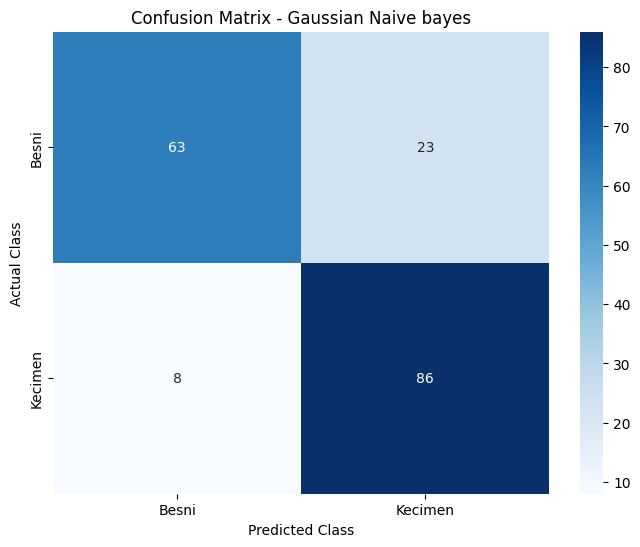

In [83]:
plt.figure(figsize=(8,6))
sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",xticklabels=label_encoder.classes_,yticklabels=label_encoder.classes_)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix - Gaussian Naive bayes")
plt.show()

In [84]:
from sklearn.metrics import accuracy_score
y_train_pred=gnb.predict(X_train)
y_test_pred=gnb.predict(X_test)
test_accuracy=accuracy_score(y_test,y_test_pred)
print("Testing Accuracy:",test_accuracy)
print("Testing Accuracy Percentage:",test_accuracy*100,"%")
train_accuracy=accuracy_score(y_train,y_train_pred)
print("Training Accuracy:",train_accuracy)
print("Training Accuracy Percentage:",train_accuracy*100,"%")
#

Testing Accuracy: 0.8277777777777777
Testing Accuracy Percentage: 82.77777777777777 %
Training Accuracy: 0.8222222222222222
Training Accuracy Percentage: 82.22222222222221 %


In [85]:
GaussianNB(priors=None)

GaussianNB()

**MAIN_HYPERPARAMETERS**

In [86]:
GaussianNB(var_smoothing=1e-9)

GaussianNB()

In [87]:
print(gnb.get_params())

{'priors': None, 'var_smoothing': 1e-09}


In [88]:
smoothing_values=[1e-12,1e-10,1e-9,1e-8,1e-7,1e-6,1e-5,1e-4,1e-3,1e-2]
result=[]
for var in smoothing_values:
    model=GaussianNB(var_smoothing=var)
    model.fit(X_train,y_train)
    prediction=model.predict(X_test)
    acc=accuracy_score(y_test,prediction)
    prec=precision_score(y_test,prediction)
    rec=recall_score(y_test,prediction)
    f1=f1_score(y_test,prediction)

    result.append([var,acc,prec,rec,f1])

In [89]:
results_df=pd.DataFrame(result,columns=["var_smoothing","accuracy","precision","recall","f1"])
print(results_df)

   var_smoothing  accuracy  precision    recall        f1
0   1.000000e-12  0.827778   0.788991  0.914894  0.847291
1   1.000000e-10  0.827778   0.788991  0.914894  0.847291
2   1.000000e-09  0.827778   0.788991  0.914894  0.847291
3   1.000000e-08  0.827778   0.788991  0.914894  0.847291
4   1.000000e-07  0.827778   0.788991  0.914894  0.847291
5   1.000000e-06  0.827778   0.788991  0.914894  0.847291
6   1.000000e-05  0.833333   0.790909  0.925532  0.852941
7   1.000000e-04  0.827778   0.783784  0.925532  0.848780
8   1.000000e-03  0.827778   0.783784  0.925532  0.848780
9   1.000000e-02  0.827778   0.783784  0.925532  0.848780


In [90]:
area=float(input("Enter Area:"))
major_axis=float(input("Enter MajorAxisLength:"))
minor_axis=float(input("Enter MinorAxisLength:"))
eccentricity=float(input("Enter Eccentricity:"))
convex_area=float(input("Enter ConvexArea:"))
extent=float(input("Enter Extent:"))
perimeter=float(input("Enter Perimeter:"))

new_sample=pd.DataFrame({
    "Area":[area],
    "MajorAxisLength":[major_axis],
    "MinorAxisLength":[minor_axis],
    "Eccentricity":[eccentricity],
    "ConvexArea":[convex_area],
    "Extent":[extent],
    "Perimeter":[perimeter],
})
prediction=gnb.predict(new_sample)
prediction_Class=label_encoder.inverse_transform(prediction)
print("Predicted Class:",prediction_Class[0])

Enter Area:2000
Enter MajorAxisLength:72
Enter MinorAxisLength:23
Enter Eccentricity:3
Enter ConvexArea:1000
Enter Extent:200
Enter Perimeter:100
Predicted Class: Besni
